In [1]:
import pandas as pd

# Load the dataset
file_path = 'advertising (1).csv'
df = pd.read_csv(file_path)

In [2]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 10 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   Daily Time Spent on Site  1000 non-null   float64
 1   Age                       1000 non-null   int64  
 2   Area Income               1000 non-null   float64
 3   Daily Internet Usage      1000 non-null   float64
 4   Ad Topic Line             1000 non-null   object 
 5   City                      1000 non-null   object 
 6   Male                      1000 non-null   int64  
 7   Country                   1000 non-null   object 
 8   Timestamp                 1000 non-null   object 
 9   Clicked on Ad             1000 non-null   int64  
dtypes: float64(3), int64(3), object(4)
memory usage: 78.3+ KB


In [3]:
df.head()

,Daily Time Spent on Site,Age,Area Income,Daily Internet Usage,Ad Topic Line,City,Male,Country,Timestamp,Clicked on Ad
0,68.95,35,61833.90,256.09,Cloned 5thgeneration orchestration,Wrightburgh,0,Tunisia,27-03-2016 00:53,0
1,80.23,31,68441.85,193.77,Monitored national standardization,West Jodi,1,Nauru,04-04-2016 01:39,0
2,69.47,26,59785.94,236.50,Organic bottom-line service-desk,Davidton,0,San Marino,13-03-2016 20:35,0
3,74.15,29,54806.18,245.89,Triple-buffered reciprocal time-frame,West Terrifurt,1,Italy,10-01-2016 02:31,0
4,68.37,35,73889.99,225.58,Robust logistical utilization,South Manuel,0,Iceland,03-06-2016 03:36,0


Here’s an initial overview of your advertising.csv dataset:

Rows & Columns: 1000 entries with 10 columns.

Columns:
**Numeric:** Daily Time Spent on Site, Age, Area Income, Daily Internet Usage, Male, Clicked on Ad

**Categorical/Text:** Ad Topic Line, City, Country, Timestamp

In [5]:
df.describe(include='object')

,Ad Topic Line,City,Country,Timestamp
count,1000,1000,1000,1000
unique,1000,969,237,997
top,Cloned 5thgeneration orchestration,Lisamouth,France,26-05-2016 15:40
freq,1,3,9,2


In [7]:
df.corr(numeric_only=True)

,Daily Time Spent on Site,Age,Area Income,Daily Internet Usage,Male,Clicked on Ad
Daily Time Spent on Site,1.000000,-0.331513,0.310954,0.518658,-0.018951,-0.748117
Age,-0.331513,1.000000,-0.182605,-0.367209,-0.021044,0.492531
Area Income,0.310954,-0.182605,1.000000,0.337496,0.001322,-0.476255
Daily Internet Usage,0.518658,-0.367209,0.337496,1.000000,0.028012,-0.786539
Male,-0.018951,-0.021044,0.001322,0.028012,1.000000,-0.038027
Clicked on Ad,-0.748117,0.492531,-0.476255,-0.786539,-0.038027,1.000000


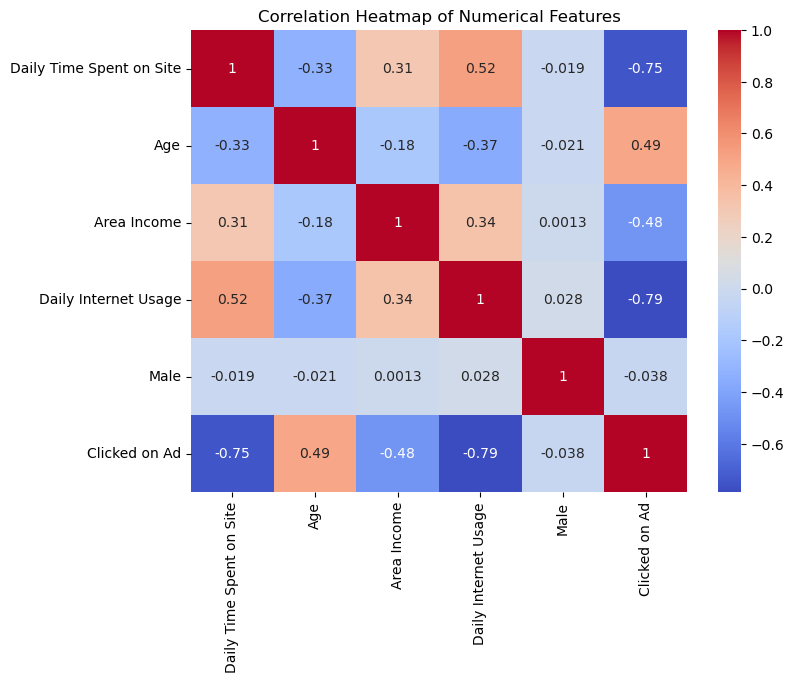

In [8]:
import matplotlib.pyplot as plt
import seaborn as sns

# Correlation heatmap of numerical features
plt.figure(figsize=(8, 6))
sns.heatmap(df.corr(numeric_only=True), annot=True, cmap='coolwarm')
plt.title('Correlation Heatmap of Numerical Features')
plt.show()


Here’s what we can observe from the EDA visuals:

**Correlation Heatmap:**

*   Daily Time Spent on Site and Daily Internet Usage have a negative correlation with each other.

*   Clicked on Ad is negatively correlated with Daily Internet Usage and positively correlated with Daily Time Spent on Site and Age.

*   No multicollinearity issues are apparent.



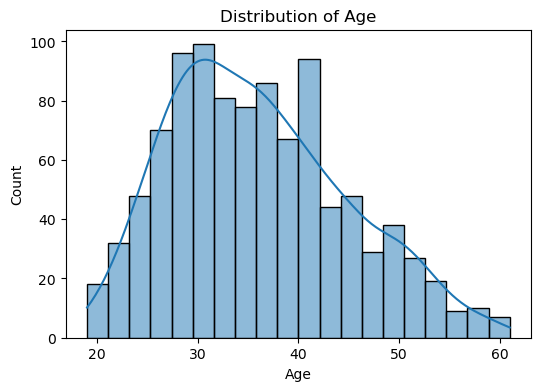

In [6]:
# Distribution of Age
plt.figure(figsize=(6, 4))
sns.histplot(df['Age'], bins=20, kde=True)
plt.title('Distribution of Age')
plt.xlabel('Age')
plt.show()



**Distribution of Age:**

Most users are clustered between 25–40 years, with a slight right skew.

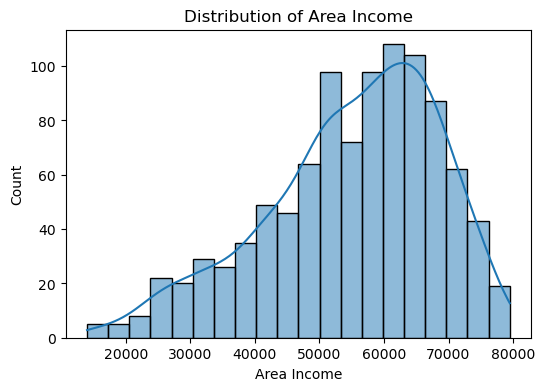

In [7]:
# Distribution of Area Income
plt.figure(figsize=(6, 4))
sns.histplot(df['Area Income'], bins=20, kde=True)
plt.title('Distribution of Area Income')
plt.xlabel('Area Income')
plt.show()



**Distribution of Area Income:**

The income distribution appears negatively skewed,More income groups between $ 55000 to $ 75000.

<Axes: xlabel='Daily Time Spent on Site', ylabel='Count'>

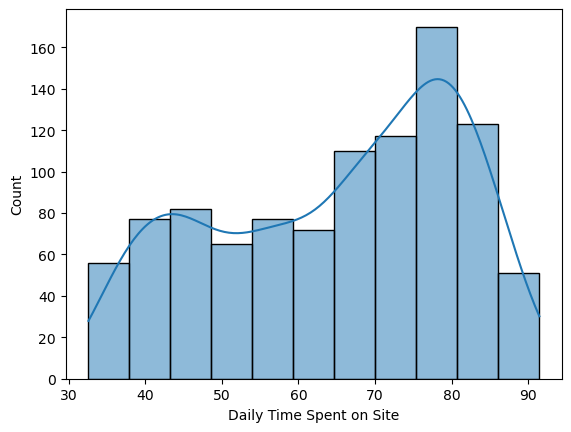

In [8]:
sns.histplot(df['Daily Time Spent on Site'],kde=True)

In [9]:
df['Daily Time Spent on Site'].kurtosis()

np.float64(-1.0955338459580628)

<Axes: xlabel='Daily Internet Usage', ylabel='Count'>

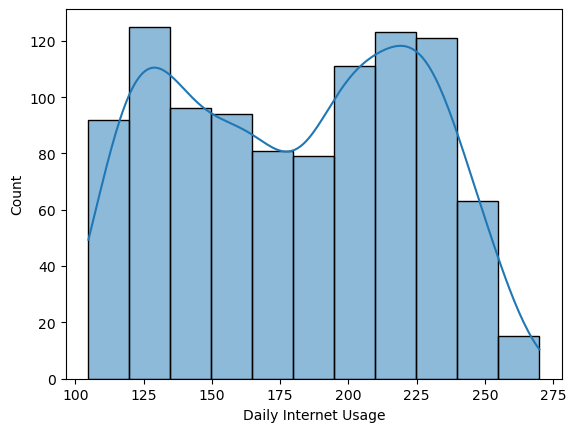

In [10]:
sns.histplot(df['Daily Internet Usage'],kde=True)

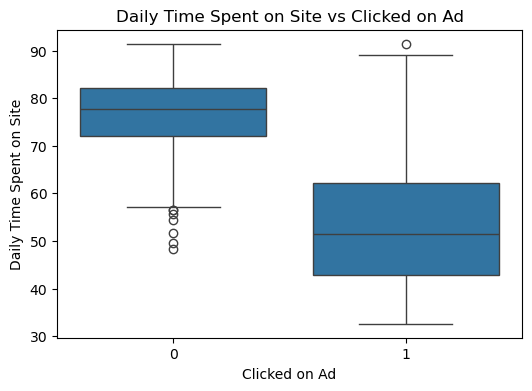

In [11]:
# Boxplot of Daily Time Spent on Site by Clicked on Ad
plt.figure(figsize=(6, 4))
sns.boxplot(x='Clicked on Ad', y='Daily Time Spent on Site', data=df)
plt.title('Daily Time Spent on Site vs Clicked on Ad')
plt.show()




**Daily Time Spent on Site vs Clicked on Ad:**
Users who clicked on the ad tend to have lower daily time spent on site, which is interesting and worth exploring further.

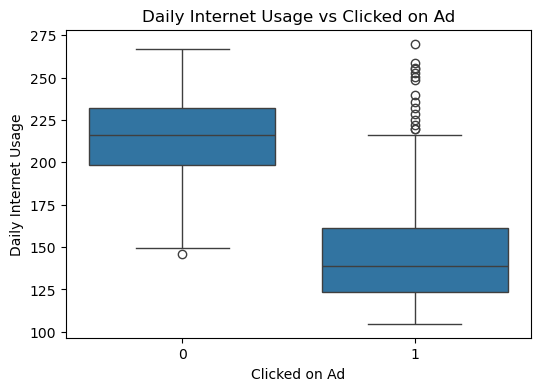

In [12]:
# Boxplot of Daily Internet Usage by Clicked on Ad
plt.figure(figsize=(6, 4))
sns.boxplot(x='Clicked on Ad', y='Daily Internet Usage', data=df)
plt.title('Daily Internet Usage vs Clicked on Ad')
plt.show()


**Daily Internet Usage vs Clicked on Ad:**

Those who clicked generally have lower daily internet usage, while non-clickers tend to have higher internet use.

In [13]:
df['Timestamp'].head(3)

0    27-03-2016 00:53
1    04-04-2016 01:39
2    13-03-2016 20:35
Name: Timestamp, dtype: object

In [14]:
df['Timestamp'] = pd.to_datetime(df['Timestamp'],format="%d-%m-%Y %H:%M")
df['Timestamp'].head(3)

0   2016-03-27 00:53:00
1   2016-04-04 01:39:00
2   2016-03-13 20:35:00
Name: Timestamp, dtype: datetime64[ns]

In [15]:
# Convert 'Timestamp' to datetime and extract new features

df['Hour'] = df['Timestamp'].dt.hour
df['Day'] = df['Timestamp'].dt.dayofweek  # Monday=0, Sunday=6

# Check the new columns
df[['Timestamp', 'Hour', 'Day']].head()


,Timestamp,Hour,Day
0,2016-03-27 00:53:00,0,6
1,2016-04-04 01:39:00,1,0
2,2016-03-13 20:35:00,20,6
3,2016-01-10 02:31:00,2,6
4,2016-06-03 03:36:00,3,4


We've successfully extracted two new features from Timestamp:

**Hour:** The hour of the day (0–23).

**Day:** The day of the week (0=Monday, 6=Sunday).

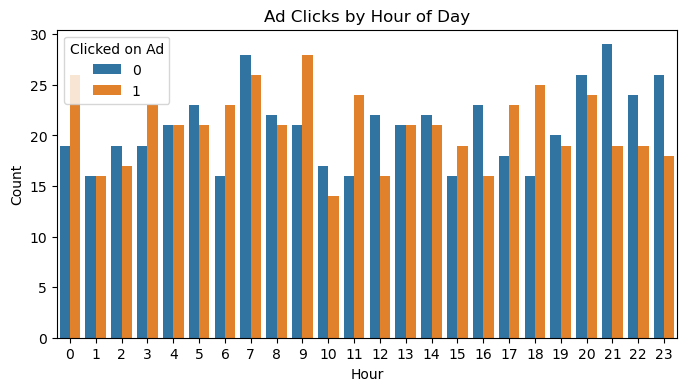

In [16]:
# Clicked on Ad by Hour
plt.figure(figsize=(8, 4))
sns.countplot(x='Hour', hue='Clicked on Ad', data=df)
plt.title('Ad Clicks by Hour of Day')
plt.xlabel('Hour')
plt.ylabel('Count')
plt.show()




**Ad Clicks by Hour of Day:**
Clicks are more frequent late at night (around 0–3 AM).

**Daytime hours (8 AM to 8 PM)** have fewer ad clicks compared to nighttime.

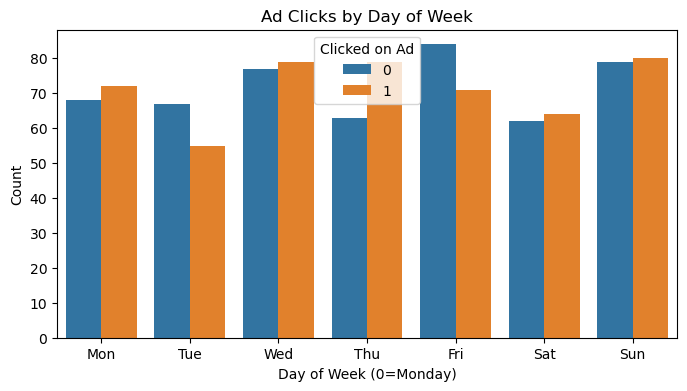

In [17]:
# Clicked on Ad by Day of Week
plt.figure(figsize=(8, 4))
sns.countplot(x='Day', hue='Clicked on Ad', data=df)
plt.title('Ad Clicks by Day of Week')
plt.xlabel('Day of Week (0=Monday)')
plt.ylabel('Count')
plt.xticks(ticks=range(7),labels=['Mon','Tue','Wed',"Thu","Fri","Sat","Sun"])
plt.show()


In [18]:
df['Ad Topic Line'].nunique()

1000

**Ad Clicks by Day of Week:**

Clicks are fairly evenly distributed across the week, with no major peaks or drops by weekday.



In [19]:

# Define feature set and target
X = df[['Daily Time Spent on Site', 'Age', 'Area Income', 'Daily Internet Usage', 'Male', 'Hour', 'Day']]
y = df['Clicked on Ad']



In [20]:
from sklearn.linear_model import LogisticRegression
# Initialize and fit Logistic Regression model
logmodel = LogisticRegression(max_iter=1200)
logmodel.fit(X, y)

# Predictions
predictions = logmodel.predict(X)



C:\Users\ExcelR Trainers\anaconda3\Lib\site-packages\sklearn\linear_model\_logistic.py:473: ConvergenceWarning: lbfgs failed to converge after 1200 iteration(s) (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT

Increase the number of iterations to improve the convergence (max_iter=1200).
You might also want to scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(


In [21]:
logmodel.score(X,y)

0.972

In [22]:
predictions

array([0, 0, 0, 0, 0, 0, 0, 1, 0, 0, 1, 0, 1, 0, 1, 1, 1, 0, 1, 1, 0, 0,
       1, 0, 1, 0, 1, 1, 1, 0, 0, 0, 1, 1, 1, 0, 1, 0, 1, 1, 0, 0, 0, 0,
       0, 1, 0, 0, 1, 1, 0, 0, 1, 1, 1, 0, 1, 1, 0, 1, 0, 0, 0, 0, 1, 0,
       1, 1, 0, 1, 1, 0, 1, 1, 1, 0, 1, 0, 1, 1, 0, 0, 1, 1, 0, 1, 0, 1,
       1, 1, 1, 1, 0, 1, 1, 0, 1, 1, 1, 0, 1, 0, 0, 0, 0, 0, 0, 1, 1, 0,
       1, 1, 0, 1, 0, 0, 1, 1, 1, 1, 0, 0, 0, 1, 1, 0, 1, 0, 0, 0, 1, 1,
       1, 0, 1, 1, 1, 1, 0, 0, 0, 1, 1, 0, 0, 1, 1, 1, 1, 1, 0, 0, 1, 0,
       0, 0, 1, 1, 0, 0, 0, 0, 0, 0, 1, 1, 1, 0, 1, 0, 1, 0, 0, 0, 1, 0,
       1, 0, 1, 0, 1, 0, 1, 0, 0, 1, 1, 0, 1, 1, 1, 1, 1, 1, 0, 1, 1, 0,
       0, 0, 0, 0, 1, 0, 0, 1, 0, 0, 1, 1, 0, 1, 0, 1, 0, 1, 1, 1, 1, 1,
       0, 0, 1, 1, 0, 1, 1, 1, 0, 0, 0, 1, 1, 0, 1, 1, 1, 1, 1, 0, 1, 1,
       0, 0, 0, 1, 1, 0, 1, 1, 0, 1, 0, 1, 1, 0, 0, 1, 0, 1, 0, 1, 1, 1,
       0, 1, 1, 0, 1, 0, 1, 0, 0, 0, 0, 1, 0, 0, 0, 0, 1, 1, 1, 0, 1, 0,
       1, 0, 1, 1, 1, 0, 1, 0, 0, 0, 0, 0, 0, 0, 0,

In [23]:
# Evaluation
from sklearn.metrics import classification_report, confusion_matrix, accuracy_score
conf_matrix = confusion_matrix(y, predictions)
accuracy = accuracy_score(y, predictions)

conf_matrix


array([[490,  10],
       [ 18, 482]])

In [24]:
print("Accuracy score:", accuracy)

Accuracy score: 0.972


In [25]:
classification_report(y,predictions)

'              precision    recall  f1-score   support\n\n           0       0.96      0.98      0.97       500\n           1       0.98      0.96      0.97       500\n\n    accuracy                           0.97      1000\n   macro avg       0.97      0.97      0.97      1000\nweighted avg       0.97      0.97      0.97      1000\n'

In [26]:
class_report = classification_report(y, predictions)
print(class_report)

              precision    recall  f1-score   support

           0       0.96      0.98      0.97       500
           1       0.98      0.96      0.97       500

    accuracy                           0.97      1000
   macro avg       0.97      0.97      0.97      1000
weighted avg       0.97      0.97      0.97      1000



In [27]:
# prompt: generate the accuracy score, recall, precision, f1 score, specificity
import numpy as np
from sklearn.metrics import recall_score, precision_score, f1_score

# Assuming 'y' and 'predictions' are already defined from the previous code

# Calculate recall
recall = recall_score(y, predictions)
print("Recall:", np.round(recall,2))

# Calculate precision
precision = precision_score(y, predictions)
print("Precision:", np.round(precision,2))

# Calculate F1-score
f1 = f1_score(y, predictions)
print("F1-score:", np.round(f1,2))

# Calculate specificity
tn, fp, fn, tp = confusion_matrix(y, predictions).ravel()
specificity = tn / (tn + fp)
print("Specificity:", np.round(specificity,2))


Recall: 0.96
Precision: 0.98
F1-score: 0.97
Specificity: 0.98


In [28]:
confusion_matrix(y, predictions).ravel()

array([490,  10,  18, 482])

In [29]:
tn, fp, fn, tp

(np.int64(490), np.int64(10), np.int64(18), np.int64(482))

In [30]:
logmodel.predict_proba(X)[:,1]

array([0.01457913, 0.00519992, 0.01181471, 0.00707813, 0.01585043,
       0.0396569 , 0.00755573, 0.99997358, 0.00200038, 0.06385098,
       0.99999642, 0.00425679, 0.99964395, 0.00794842, 0.9999907 ,
       0.93553741, 0.9999937 , 0.02533153, 0.99998917, 0.99970532,
       0.00203225, 0.00295397, 0.99999885, 0.00360908, 0.99736725,
       0.00582789, 0.99979125, 0.99994987, 0.99957792, 0.03326761,
       0.02148686, 0.00922002, 0.99998978, 0.95205262, 0.99998019,
       0.00488939, 0.99979109, 0.02791335, 0.99996326, 0.9999974 ,
       0.00643445, 0.02091375, 0.00912611, 0.00277768, 0.00795397,
       0.9999681 , 0.06425437, 0.02126994, 0.99996001, 0.99997579,
       0.01089744, 0.00237289, 0.9999137 , 0.99986291, 0.99960817,
       0.03319202, 0.72507705, 0.99999597, 0.00568311, 0.99999798,
       0.08352831, 0.00689538, 0.0939598 , 0.01872908, 0.99980141,
       0.05608518, 0.9998074 , 0.99887543, 0.00651034, 0.99555548,
       0.99831066, 0.07629007, 0.94367083, 0.99998873, 0.99993

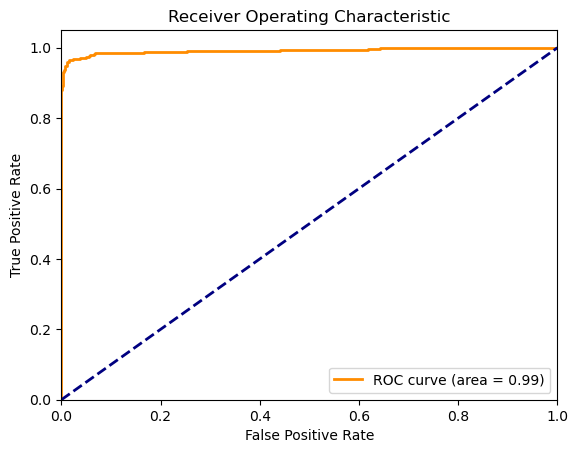

AUC score: 0.9920319999999999


In [31]:

from sklearn.metrics import roc_curve, auc

# Predictions on the test set
predictions = logmodel.predict(X)
y_pred_proba = logmodel.predict_proba(X)[:,1]

# ROC Curve and AUC
fpr, tpr, thresholds = roc_curve(y, y_pred_proba)
roc_auc = auc(fpr, tpr)

plt.figure()
plt.plot(fpr, tpr, color='darkorange', lw=2, label='ROC curve (area = %0.2f)' % roc_auc)
plt.plot([0, 1], [0, 1], color='navy', lw=2, linestyle='--')
plt.xlim([0.0, 1.0])
plt.ylim([0.0, 1.05])
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('Receiver Operating Characteristic')
plt.legend(loc="lower right")
plt.show()

print(f"AUC score: {roc_auc}")


In [34]:
tpr

array([0.   , 0.002, 0.88 , 0.88 , 0.892, 0.892, 0.932, 0.932, 0.938,
       0.938, 0.948, 0.948, 0.96 , 0.96 , 0.964, 0.964, 0.968, 0.968,
       0.97 , 0.97 , 0.972, 0.972, 0.974, 0.974, 0.976, 0.976, 0.978,
       0.978, 0.98 , 0.98 , 0.982, 0.982, 0.984, 0.984, 0.986, 0.986,
       0.988, 0.988, 0.99 , 0.99 , 0.992, 0.992, 0.994, 0.994, 0.996,
       0.996, 0.998, 0.998, 1.   , 1.   ])